<a href="https://colab.research.google.com/github/ejcalvillo/Ospetal-Hospital-Management-Database/blob/main/HW3_skeleton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW3 Basic Statistics: histogram, SEM, CI, Correlation, Probabilities

To complete this homework, you need to download the diseases.csv file, which contain the monthly number of new cases of measles, mumps, and chicken pox, respectively, for New York City during the years 1931-1971 (for a total of 41 years). The data file contains 123 rows and 12 columns. Each column represents a month from Jan to Dec. The first 41 rows are the number of new measles cases in each year during that period, the next 41 rows are for mumps, and the remaining 41 rows are chicken pox. The rows are ordered by the years in chronical order.

(The homework script will download the file from github and use directly, or you can download the file from blackboard and save it in the same local folder as your homework script.)

Complete the python script skeleton to analyze the data for the following tasks. For your information, data has been loaded with the Pandas package and reorganized into a Numpy 3d array of shape (3, 41, 12), where the first dimension represents the three diseases. Several other variables are also defined for your convenience.

### Import necessary modules. You can add more if necessary

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from math import sqrt

### load the data and setup some variables

After reshape, data is a numpy ndarray of shape (3,41,12) for the three diseases, 41 years and 12 months

In [5]:
# this is the order of the three diseases in the 3d array, data
diseases = ['Measles', 'Mumps', 'ChickenPox']
# define three variables for the indices of the three diseases for easier
[me, mu, ch] = [0, 1, 2]
year = np.arange(1931, 1972)
month = np.arange(1, 13)

url = 'diseases.csv'
# comment out the following to read from local file instead online
url = 'https://raw.githubusercontent.com/jianhuaruan/3753/main/' + url
data = pd.read_csv(url,header=None).values
data = data.reshape([3, 41, 12]) #data[0], data[1], and data[2] is for measles, mumps, and chickenpox

### Q0 (Example). Yearly trend: total annual cases
Calculate the total number of cases for each year and plot as a function of year

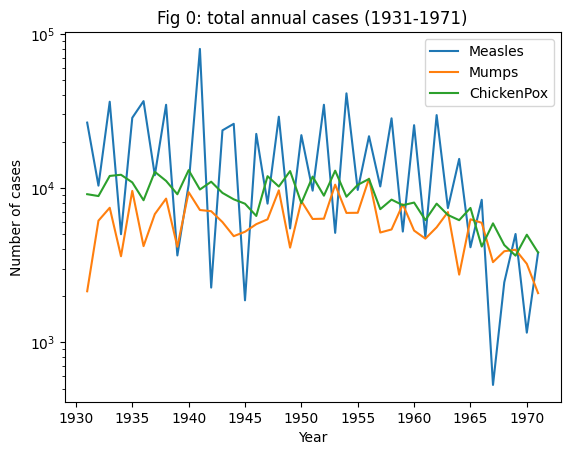

In [18]:
plt.figure()
# data is of shape (3, 41, 12), so annualCases is of shape(3, 41)
annualCases = data.sum(axis=2)
# this plot each column of annualCases.T against years
plt.semilogy(year, annualCases.T)
plt.xlabel('Year')
plt.ylabel('Number of cases')
plt.title('Fig 0: total annual cases (1931-1971)')
plt.legend(diseases)
plt.show()

Q1.Histogram of total annual cases (10 points)
Plot a histogram of total annual cases for each disease, using the hist function with 5 bins for each disease and bin boundaries determined automatically

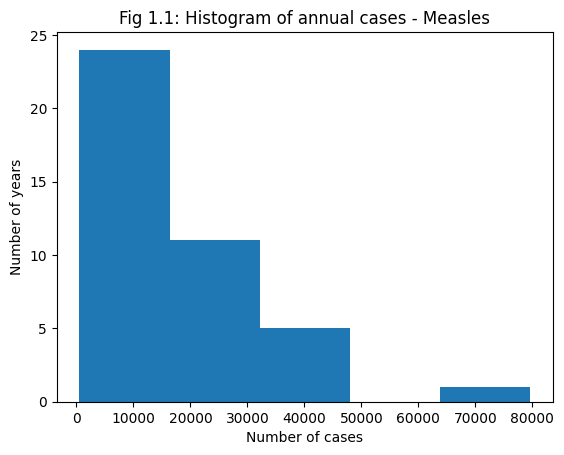

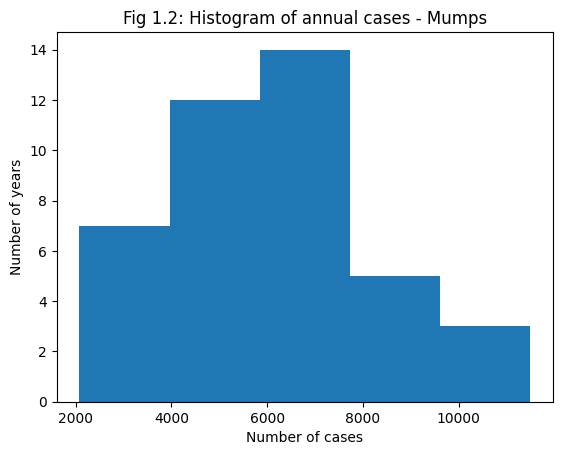

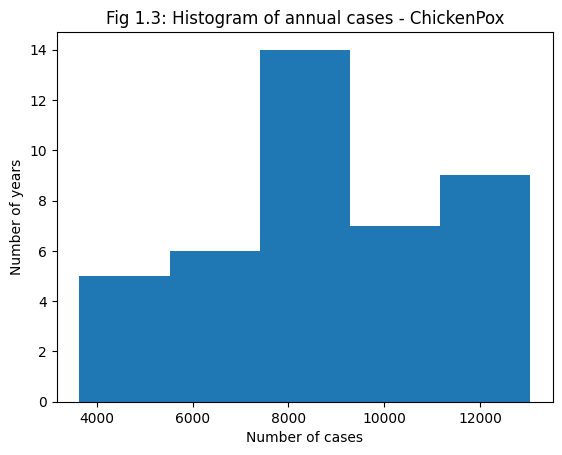

In [20]:

for i in range(3):

  plt.figure()
  plt.hist(annualCases[i], bins=5)
  plt.title('Fig 1.' + str(i+1) + ': Histogram of annual cases - ' + diseases[i])
  plt.xlabel('Number of cases')
  plt.ylabel('Number of years')
  plt.show()



### Q2 Standard error of the mean, 95% confidence interval (10 points)

Calculate the average (mean) number of cases per year for each disease, the standard error of the mean (SEM), and the 95% confidence interval (CI) of the mean, and make two figures using the errorbar function: one shows the mean & SEM of each disease, and the other shows the mean & 95% CI for each disease. use the function plt.xticks to change xtick labels to strings.


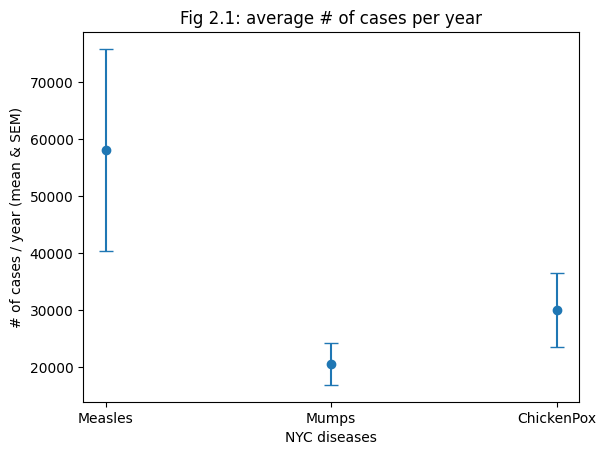

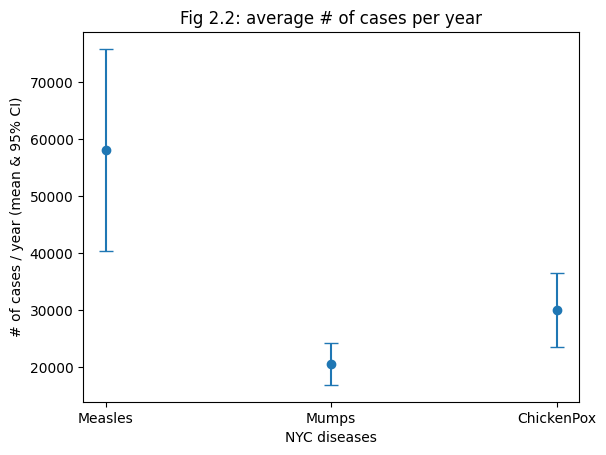

In [98]:


means_vals = annualCases.mean(axis=1)
sem_vals = annualCases.std(axis=1,ddof=1) / np.sqrt(41)
ci95 = 1.96 * sem_vals

plt.figure()
plt.errorbar(range(3), means_vals, yerr=ci95, fmt='o', capsize=5)

plt.xlabel('NYC diseases')
plt.xticks(range(3), diseases)
plt.ylabel('# of cases / year (mean & SEM)')
plt.title('Fig 2.1: average # of cases per year')
plt.show()

plt.figure()

plt.errorbar(range(3), means_vals, yerr=ci95, fmt='o', capsize=5)
plt.xticks(range(3), diseases)

plt.xlabel('NYC diseases')
plt.ylabel('# of cases / year (mean & 95% CI)')
plt.title('Fig 2.2: average # of cases per year')
plt.show()



### % Q3 Correlation between total annual cases of measles vs mumps (10 points)

Q3.1 Scatter plot the total annual measels cases against total annual mumps cases. In other words, you are scatter plotting two vectors, x, and y, each of which has 41 values, representing the total number of measles or mumps cases in year 1931, 1932, etc. (This is the same data used to plot the blue and orange curves in Fig 0.)

Q3.2 Calculate the Pearson correlation coefficient as well as the spearman correlation coefficient between the total annual mumps cases and total annual mumps cases (the two vectors x and y you plotted in Q3.1), print out the correlation coefficient values, or display the values (with a precision 0.0001) in the figure (bonus points). (Decide the x and y positions ad hoc from your fig).

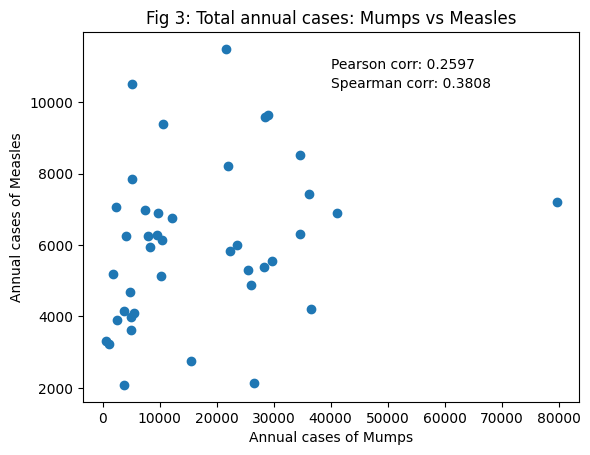

Pearson correlation: %.4f
Spearman correlation: %.4f 


In [64]:
# 3.1 scatter plot

plt.figure()
plt.scatter(annualCases[mu], annualCases[me])
annualCases = data.sum(axis=2)

plt.xlabel('Annual cases of ' + diseases[me])
plt.ylabel('Annual cases of ' + diseases[mu])
plt.title('Fig 3: Total annual cases: %s vs %s' %(diseases[me], diseases[mu]))

# 3.2 compute and display pearson correlation coefficient & Spearman correlation
pearson_corr, _ = stats.pearsonr(annualCases[mu], annualCases[me])
spearman_corr, _ = stats.spearmanr(annualCases[mu], annualCases[me])
plt.text(0.5, 0.9, f'Pearson corr: {pearson_corr:.4f}', transform=plt.gca().transAxes, fontsize=10)
plt.text(0.5, 0.85, f'Spearman corr: {spearman_corr:.4f}', transform=plt.gca().transAxes, fontsize=10)
plt.show()

print('Pearson correlation: %.4f' )
print('Spearman correlation: %.4f ')


### % Q4 Seasonal trend of the diseases (5 points)

For each disease, calculate the average number of cases occurred in a month, breaking into Janurary, Feburary, et. The resulting matrix, denoted as C, will have a size of 3 x 12. Each row in the matrix corresponds to a specific disease, and each column corresponds to a month. The value in the matrix (Cij) represents the number of cases of disease i that occurred in month j, averaged over all 41 years. Plot the vectors as a line graph against months.

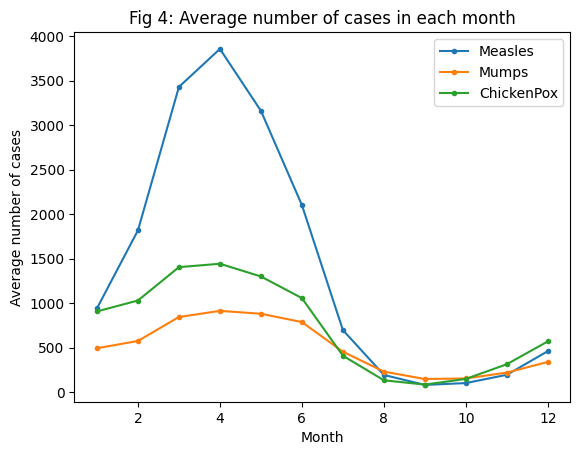

In [69]:
plt.figure()
C = data.mean(axis=1)

for i in range(C.shape[0]):
    plt.plot(month, C[i],marker='.', label=diseases[i])
    plt.legend(diseases)

plt.xlabel('Month')
plt.ylabel('Average number of cases')
plt.title('Fig 4: Average number of cases in each month')
plt.show()



### % Q5 Correlation between average monthly cases of measles vs mumps. (10 points)

Q5.1 Scatter plot the average monthly mumps cases against the average monthly mumps cases. In other words, you are scatter plotting two vectors, x, and y, each of which has 12 values, representing the average number of measles or mumps cases in Janurary, Februrary, etc. (This is the same data used to plot the blue and orange curves in Fig 4.)

Q5.2 Calculate the Pearson correlation coefficient as well as the spearman correlation coefficient between the mean monthly mumps cases and mean monthly mumps cases (the two vectors x and y you plotted in Q5.1), print out the correlation coeffients, or display the values (with a precision 0.0001) in the figure (bonus points).

In [8]:
# Q5.1 scatter plot
plt.figure()

x = C[me]
y = C[mu]

# Create a scatter plot

plt.scatter(x,y)
plt.xlabel('Average monthly cases of ' + diseases[me])
plt.ylabel('Average monthly cases of ' + diseases[mu])
plt.title(f'Fig 5: Average monthly cases of {diseases[me]} vs {diseases[mu]}')

# Calculate correlation coefficients
pearson_corr, _ = stats.pearsonr(x, y)
spearman_corr, _ = stats.spearmanr(x, y)

# Display correlation coefficients
plt.text(0.7 * max(x), 0.3 * max(y), f'Pearson corr: {pearson_corr:.4f}', transform=plt.gca().transAxes, fontsize=10)
plt.text(0.7 * max(x), 0.25 * max(y), f'Spearman corr: {spearman_corr:.4f}', transform=plt.gca().transAxes, fontsize=10)
plt.show()

print('Pearson corr: %.4f' )
print('Spearman corr: %.4f')

NameError: name 'C' is not defined

<Figure size 640x480 with 0 Axes>

### % Q6 Correlation between measles and mumps, overall trend (15 points)

For this analysis, we will consider each month in the dataset as a separate data point (a total of 41 x 12 = 492), instead of computing average or total of multiple years/months. You may need the flat function or something similar (last slide in the numpy lecture).

Q6.1 Plot the monthly cases of measles and monthly cases of mumps versus the month indices (from 0 to 491) as line graphs.

Q6.2 Scatter plot the monthly cases of measles vs monthly cases of mumps. Compute the pearson and spearman correlation coefficients and display.

Q6.3 scatter plot in loglog scale, and compute and display the two correlation coefficients after log transformation of the values.



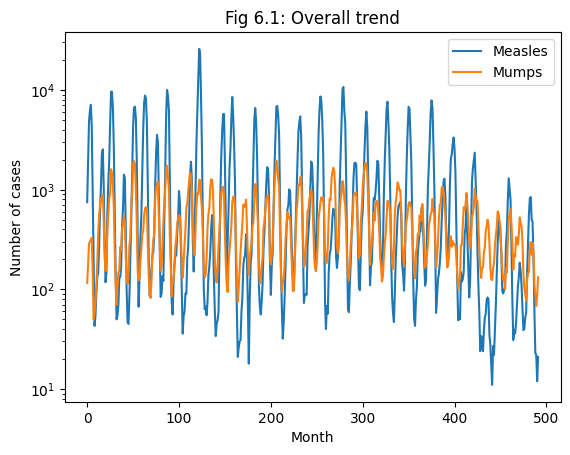

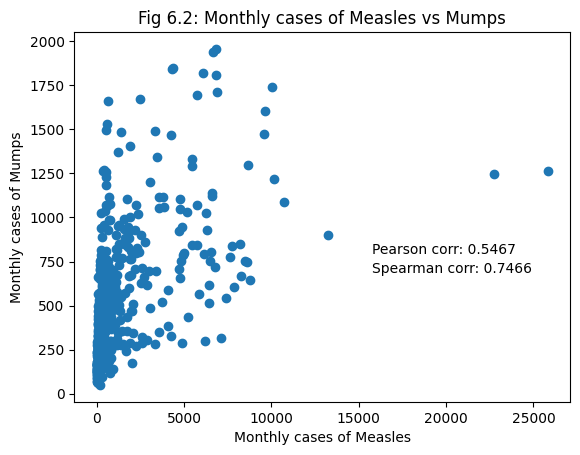

Pearson correlation in orignal space: %.4f
Spearman correlation in original space: %.4f 


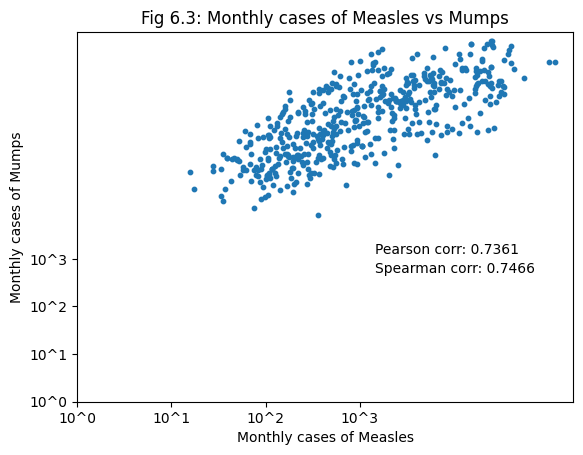

Pearson correlation in log space: %.4f
Spearman correlation in log space: %.4f 


In [41]:
# 6.1 plot overall trend with data from all 492 months


plt.figure()
plt.plot(data[me].flatten(), label=diseases[me])
plt.plot(data[mu].flatten(), label=diseases[mu])
plt.legend(diseases)
plt.yscale('log')
plt.xlabel('Month')
plt.ylabel('Number of cases')
plt.title('Fig 6.1: Overall trend')
plt.show()


# 6.2 scatter plot and correlation in original scale


plt.figure()
plt.scatter(data[me].flatten(), data[mu].flatten())
plt.xlabel('Monthly cases of ' + diseases[me])
plt.ylabel('Monthly cases of ' + diseases[mu])
plt.title('Fig 6.2: Monthly cases of %s vs %s' %(diseases[me], diseases[mu]))


# compute and display Pearson correlation coefficient & Spearman correlation
pearson_corr, _ = stats.pearsonr(data[me].flatten(), data[mu].flatten())
spearman_corr, _ = stats.spearmanr(data[me].flatten(), data[mu].flatten())
plt.text(0.6, 0.4, f'Pearson corr: {pearson_corr:.4f}', transform=plt.gca().transAxes, fontsize=10)
plt.text(0.6, 0.35, f'Spearman corr: {spearman_corr:.4f}', transform=plt.gca().transAxes, fontsize=10)


plt.show()

print('Pearson correlation in orignal space: %.4f' )
print('Spearman correlation in original space: %.4f ' )



# 6.3 scatter plot and correlation in log scale
plt.figure()
plt.scatter(np.log(data[me].flatten()), np.log(data[mu].flatten()))
plt.xticks([0,2,4,6] ,[ '10^0', '10^1', '10^2', '10^3'])
plt.yticks([0,1,2,3],[ '10^0', '10^1', '10^2', '10^3'])

plt.xlabel('Monthly cases of ' + diseases[me])
plt.ylabel('Monthly cases of ' + diseases[mu])
plt.title('Fig 6.3: Monthly cases of %s vs %s' %(diseases[me], diseases[mu]))


# compute and display Pearson correlation coefficient & Spearman correlation
pearson_corr, _ = stats.pearsonr(np.log(data[me].flatten()), np.log(data[mu].flatten()))
spearman_corr, _ = stats.spearmanr(np.log(data[me].flatten()), np.log(data[mu].flatten()))
plt.text(0.6, 0.4, f'Pearson corr: {pearson_corr:.4f}', transform=plt.gca().transAxes, fontsize=10)
plt.text(0.6, 0.35, f'Spearman corr: {spearman_corr:.4f}', transform=plt.gca().transAxes, fontsize=10)

plt.show()

print('Pearson correlation in log space: %.4f')
print('Spearman correlation in log space: %.4f ')



### Q7. Calculate the following probabilities (20 points)
You can either use an explicit formula (using python as a calculator) or a function from scipy.stats.binom or scipy.stats.norm.

You don't need to do both. Choose whichever is more convenient.

See examples below.

In [37]:
# example 1: Roll a fair die 10 times, what is the probability of seeing ten 6's in a roll?

# two options:

(1/6)**10 # option 1; using python as a colculator

# option 2. using the pmf function from binom.pmf. uncomment below to see
stats.binom.pmf(10, 10, 1/6)

np.float64(1.6538171687920194e-08)

In [ ]:
# example 2: Roll a fair die 10 times, What is the probability of seeing exactly three 6's?
stats.binom.pmf(3, 10, 1/6)

In [49]:
# example 3: Roll a fair die 5 times, what is the probability of seeing at least three 6's?
# option 1
stats.binom.pmf([3, 4, 5], 5, 1/6).sum()

# option 2. uncomment below to see
#1 - stats.binom.cdf(2, 5, 1/6)

np.float64(0.03549382716049381)

In [50]:
# Q7.1 Toss a fair coin 10 times, what is the probability of seeing 10 heads in a row?
p1= stats.binom.pmf(10,10,1/2)
print('Probability of seeing 10 heads in a row: %.6f' % p1)


np.float64(0.0009765625)

In [51]:
# Q7.2 Toss a loaded coin (p_head = 0.9) 10 times, what is the probability of seeing 10 heads in a row?

p2 = stats.binom.pmf(10,10,0.9)
print('Probability of seeing 10 heads in a row with a loaded coin: %.6f' % p2)

np.float64(0.3486784401000001)

In [ ]:
# Q7.3 Toss a fair coin 10 times, what is the probability of seeing 8 heads?
p3 = stats.binom.pmf(10,8,1/2)
print('Probability of seeing 8 heads in after 10 tosses: %.6f' % p3)

In [38]:
# Q7.4 Toss a loaded coin (p_head = 0.9) 10 times, what is the probability of seeing at least 8 heads?

p4 = 1 - stats.binom.pmf(8,10,0.9)
print('Probability of seeing at least 8 heads with a loaded coint: %.6f' % p4)

Probability of seeing at least 8 heads with a loaded coint: nan


In [42]:
# Q7.5 Given a box of coins where exactly half of the coins are fair coins and the other half are loaded coins (phead = 0.9),
# if you pick one coin from the box and toss it ten times, what is the probability to see ten heads in a row?

p5 = stats.binom.pmf(10,10,1/2)*0.5 + stats.binom.pmf(10,10,0.9)*0.5
print('Probability that the coin is loaded given 10 heads in a row: %.6f' % p5)

Probability that the coin is loaded given 10 heads in a row: 0.174828


In [ ]:
# Q7.6 Given the box of coins described in Q7.5, if you pick a coin randomly and toss it 10 times and get ten heads in a row,
# how likely this is a loaded coin? (Use the Bayesian formula.

p6 = stats.binom.pmf(10,10,0.9)
print('Probability that the coin is loaded given 10 heads in a row: %.6f' % p6)

In [48]:
# Q7.7 You randomly picked another coin from the box and tolls it 10 times. You get 8 heads. How likely this is a loaded coin?
p8heads_loaded = stats.binom.pmf(8,10,0.9)
p8heads_fair = stats.binom.pmf(8,10,1/2)
p7 = (p8heads_loaded*0.5) / (p8heads_loaded*0.5 + p8heads_fair*0.5)
print('Probability that the coin is loaded given 8 heads in 10 tosses: %.6f' % p7)

Probability that the coin is loaded given 8 heads in 10 tosses: 0.815088


In [ ]:
# Q7.8 Draw a random number from a standard normal distribution (mean = 0, std = 1), what is the probability of getting a number <= -1?
# use stats.norm.cdf
p8 = stats.norm.cdf(-1,0,1)
print('Probability of getting a number <= -1 from standard normal distribution: %.6f' % p8)

In [46]:
# Q7.9 Draw a random number from a standard normal distribution (mean = 0, std = 1), what is the probability of getting a number > 2?

p9 = 1- stats.norm.cdf(2,0,1)
print('Probability of getting a number > 2 from standard normal distribution: %.6f' % p9)

Probability of getting a number > 2 from standard normal distribution: 0.977250


In [45]:
# Q7.10 Draw a random number from a normal distribution (mean = 50, std = 10), what is the probability of getting a number > 65?
x = stats.norm.cdf(65,50,10)
p10 = x = 1-x
print('Probability of getting a number > 65 from N(50,10) distribution: %.6f' % p10)


Probability of getting a number > 65 from N(50,10) distribution: 0.066807
